In [1]:
import warnings
warnings.filterwarnings("ignore")

In [2]:
import nbimporter
from bike_sharing_data import get_bike_sharing

X_train, X_test, y_train, y_test = get_bike_sharing()

print("Training data:", X_train.shape)
print("Testing data:", X_test.shape)

Training data: (13903, 12)
Testing data: (3476, 12)


In [3]:
from sklearn.linear_model import LinearRegression

model = LinearRegression()

In [4]:
# Train
model.fit(X_train, y_train)

print("Model training completed!")

Model training completed!


In [5]:
y_train_pred = model.predict(X_train)
y_test_pred = model.predict(X_test)

In [6]:
from sklearn.metrics import (
    mean_absolute_error,
    mean_squared_error,
    r2_score
)
import numpy as np

# Evaluation on testing data
mae = mean_absolute_error(y_test, y_test_pred)

mse = mean_squared_error(y_test, y_test_pred)

rmse = np.sqrt(mse)

r2 = r2_score(y_test, y_test_pred)

print("Model Evaluation on Test Data")
print("--------------------------------")
print("MAE :", mae)
print("MSE :", mse)
print("RMSE:", rmse)
print("R2 Score:", r2)

Model Evaluation on Test Data
--------------------------------
MAE : 104.8033508955442
MSE : 19379.828367651717
RMSE: 139.21145199893476
R2 Score: 0.38798115831391344


In [7]:
train_r2 = r2_score(y_train, y_train_pred)

# The large difference suggests possible overfitting.
print("Training R2:", train_r2)
print("Testing R2:", r2)

Training R2: 0.3888110962633091
Testing R2: 0.38798115831391344


In [8]:
import matplotlib.pyplot as plt
import seaborn as sns

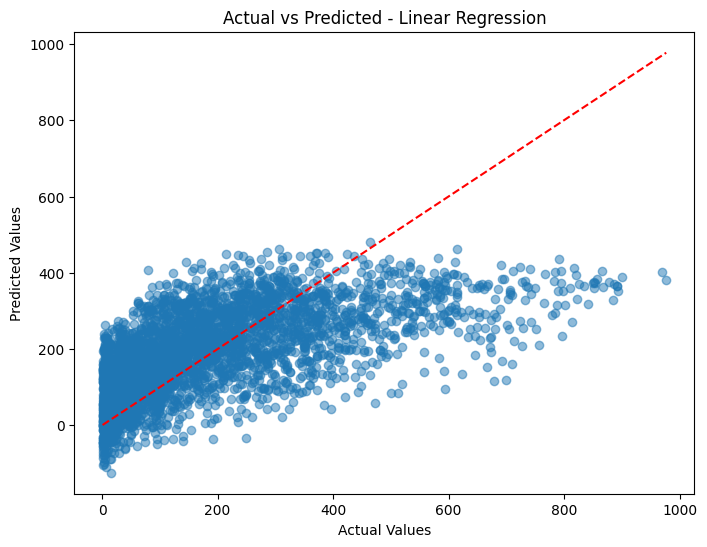

In [9]:
# Plot: Actual vs Predicted values
plt.figure(figsize=(8, 6))

plt.scatter(y_test, y_test_pred, alpha=0.5)

# Perfect prediction reference line
plt.plot(
    [y_test.min(), y_test.max()],
    [y_test.min(), y_test.max()],
    'r--'
)

plt.xlabel("Actual Values")
plt.ylabel("Predicted Values")
plt.title("Actual vs Predicted - Linear Regression")

plt.show()

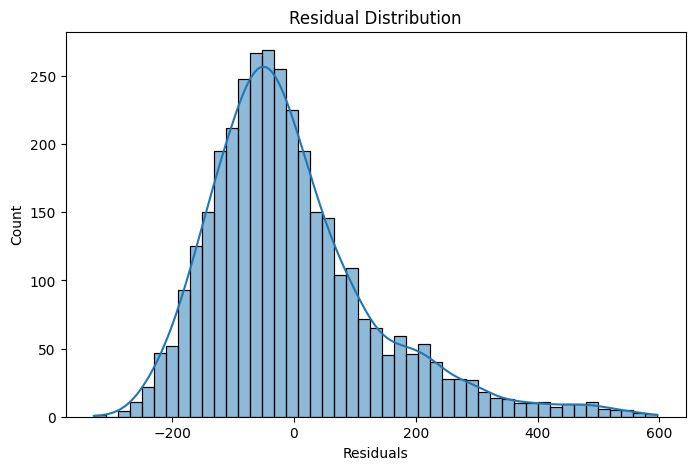

In [10]:
# Plot: Residual distribution
# Residual = Actual value − Predicted value.

residuals = y_test - y_test_pred

plt.figure(figsize=(8, 5))

sns.histplot(residuals, kde=True)

plt.xlabel("Residuals")
plt.title("Residual Distribution")

plt.show()

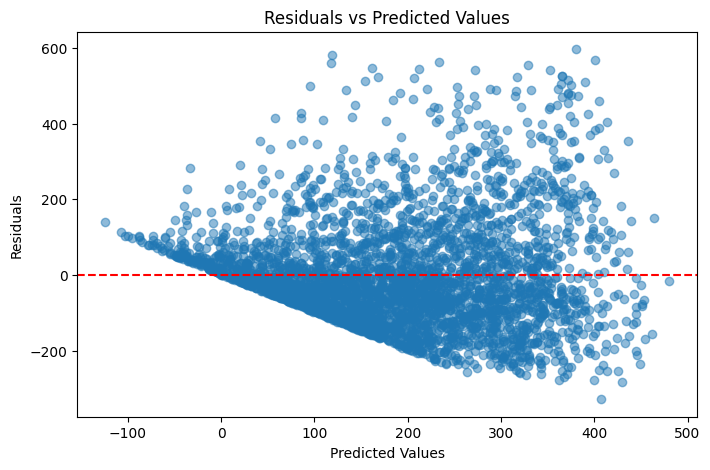

In [11]:
# Plot: Residuals vs Predicted values
plt.figure(figsize=(8, 5))

plt.scatter(y_test_pred, residuals, alpha=0.5)

plt.axhline(y=0, color='red', linestyle='--')

plt.xlabel("Predicted Values")
plt.ylabel("Residuals")
plt.title("Residuals vs Predicted Values")

plt.show()

In [12]:
import pandas as pd
from bike_sharing_data import bike_sharing_dataset

X, y, _ = bike_sharing_dataset()

X.drop(columns=["dteday"], inplace=True)

# Check model coefficients
coefficients = pd.DataFrame({
    'Feature': X.columns,
    'Coefficient': model.coef_
})

coefficients = coefficients.sort_values(
    by='Coefficient',
    ascending=False
)

display(coefficients)

,Feature,Coefficient
9,atemp,204.992854
8,temp,99.048437
1,yr,82.844875
11,windspeed,34.490649
0,season,20.517992
3,hr,7.662499
6,workingday,3.904188
5,weekday,1.777640
2,mnth,0.119190
7,weathersit,-3.433190
